In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nusratjahannawal/image-processing-assignment/Input_image.jpg


In [2]:
# Mathematical Morphological Image Enhancement

#Image Processing Assignment**

#This notebook implements mathematical morphological image processing
#using custom functions for erosion, dilation, opening, closing,
#White Top-Hat, Black Top-Hat, and final morphological enhancement.

#The input image and structuring elements are based on the assigned paper.

In [3]:
import matplotlib.pyplot as plt
from PIL import Image

In [4]:
image_path = "/kaggle/input/datasets/nusratjahannawal/image-processing-assignment/Input_image.jpg"

image = Image.open(image_path)

print("Image size:", image.size)
print("Image mode:", image.mode)

Image size: (320, 320)
Image mode: RGB


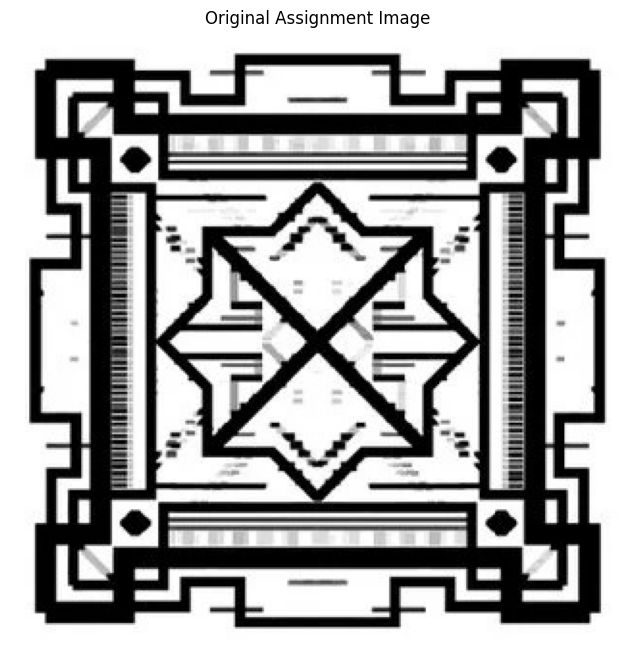

In [5]:
plt.figure(figsize=(10, 8))

plt.imshow(image, cmap="gray")
plt.title("Original Assignment Image")
plt.axis("off")

plt.show()

In [6]:
img = np.array(image)

print("Array shape:", img.shape)
print("Data type:", img.dtype)
print("Minimum pixel value:", img.min())
print("Maximum pixel value:", img.max())

Array shape: (320, 320, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


In [7]:
unique_values = np.unique(img)

print("Number of unique pixel values:", len(unique_values))
print("Unique pixel values:", unique_values[:50])

Number of unique pixel values: 256
Unique pixel values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]


In [8]:
#Separating three RGB channels
R = img[:, :, 0]
G = img[:, :, 1]
B = img[:, :, 2]

print("Red channel range:", R.min(), "to", R.max())
print("Green channel range:", G.min(), "to", G.max())
print("Blue channel range:", B.min(), "to", B.max())

Red channel range: 0 to 255
Green channel range: 0 to 255
Blue channel range: 0 to 255


In [9]:
#Manually RGB to grayscale conversion
gray = (
    0.299 * R +
    0.587 * G +
    0.114 * B
)

gray = gray.astype(np.uint8)

print("Grayscale shape:", gray.shape)
print("Grayscale range:", gray.min(), "to", gray.max())

Grayscale shape: (320, 320)
Grayscale range: 0 to 255


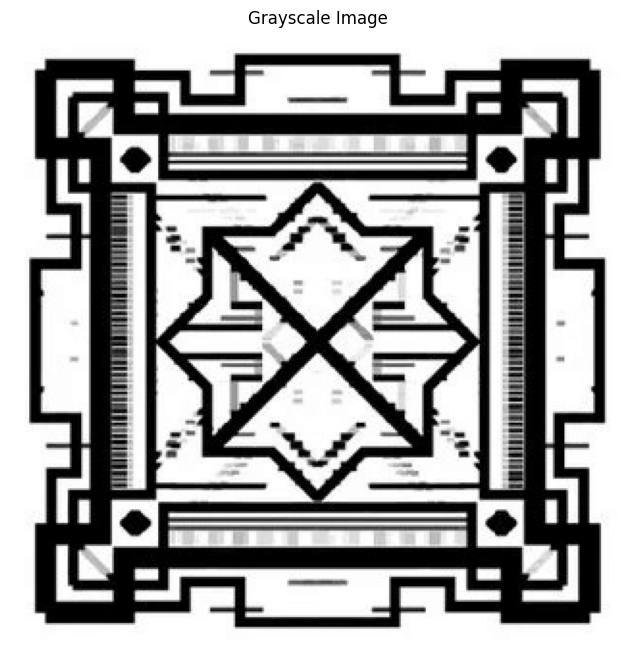

In [10]:
plt.figure(figsize=(8, 8))

plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.show()

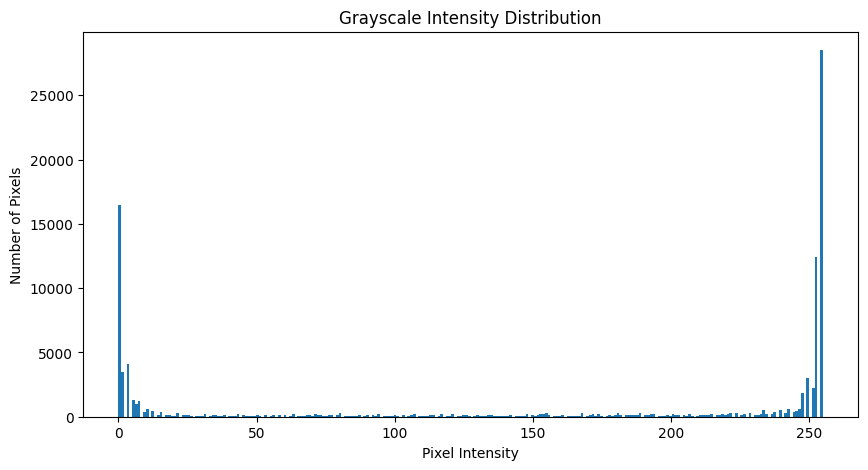

In [11]:
plt.figure(figsize=(10, 5))

plt.hist(gray.ravel(), bins=256)

plt.title("Grayscale Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")

plt.show()

In [12]:
print("Mean intensity:", gray.mean())
print("Median intensity:", np.median(gray))
print("Standard deviation:", gray.std())

Mean intensity: 156.281591796875
Median intensity: 237.0
Standard deviation: 112.08261519918267


In [13]:
#Manual Binary Thresholding

def manual_threshold(image, threshold):
    binary = np.zeros(image.shape, dtype=np.uint8)

# Dark pixels becoming foreground(1)
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            if image[i, j] < threshold:
                binary[i, j] = 1

    return binary


threshold_value = 128

binary = manual_threshold(gray, threshold_value)

print("Binary image shape:", binary.shape)
print("Unique binary values:", np.unique(binary))
print("Foreground pixels:", np.sum(binary == 1))
print("Background pixels:", np.sum(binary == 0))

Binary image shape: (320, 320)
Unique binary values: [0 1]
Foreground pixels: 38931
Background pixels: 63469


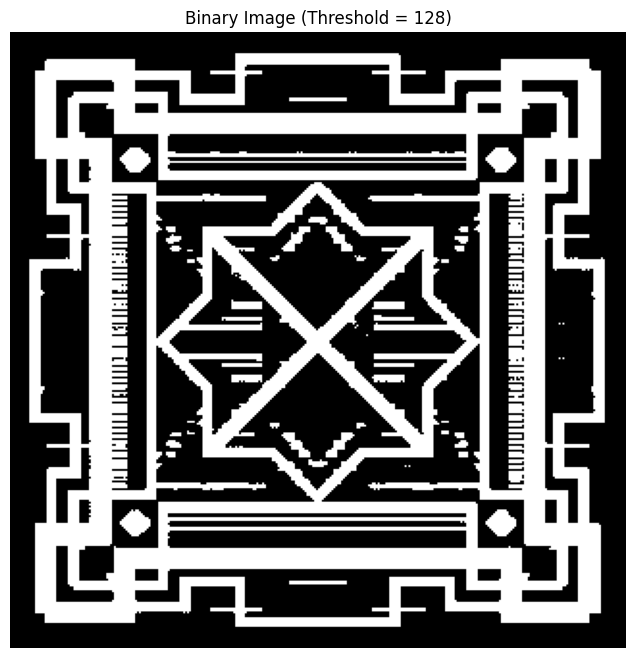

In [14]:
#Display Binary Image
plt.figure(figsize=(8, 8))
plt.imshow(binary, cmap="gray", vmin=0, vmax=1)
plt.title("Binary Image (Threshold = 128)")
plt.axis("off")
plt.show()

In [15]:
#Structuring Element (4 rows x 8 columns, height=4, width=8)
SE = np.ones((4, 8), dtype=np.uint8)
print("SE shape:", SE.shape)
print(SE)

SE shape: (4, 8)
[[1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]]


In [16]:
#Manual Erosion

def erosion(image, se, anchor=None):

    se_h, se_w = se.shape

    if anchor is None:
        anchor = (se_h // 2, se_w // 2)

    a_i, a_j = anchor

    
    offsets = np.argwhere(se == 1) - np.array([a_i, a_j])

    
    padded = np.pad(
        image,
        ((se_h - 1, se_h - 1), (se_w - 1, se_w - 1)),
        mode="constant", constant_values=0
    )

    output = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            values = []

            for di, dj in offsets:
                values.append(
                    padded[
                        i + se_h - 1 + di,
                        j + se_w - 1 + dj
                    ]
                )

            if np.all(np.array(values) == 1):
                output[i, j] = 1

    return output


eroded = erosion(binary, SE)

print("Eroded foreground pixels:", np.sum(eroded == 1))

Eroded foreground pixels: 12111


In [17]:
#Manual Dilation

def dilation(image, se, anchor=None):

    se_h, se_w = se.shape

    if anchor is None:
        anchor = (se_h // 2, se_w // 2)

    a_i, a_j = anchor

    
    offsets = np.argwhere(se == 1) - np.array([a_i, a_j])

    
    padded = np.pad(
        image,
        ((se_h - 1, se_h - 1), (se_w - 1, se_w - 1)),
        mode="constant", constant_values=0
    )

    output = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            values = []

            for di, dj in offsets:
                values.append(
                    padded[
                        i + se_h - 1 - di,
                        j + se_w - 1 - dj
                    ]
                )

            if np.any(np.array(values) == 1):
                output[i, j] = 1

    return output


dilated = dilation(binary, SE)

print("Dilated foreground pixels:", np.sum(dilated == 1))

Dilated foreground pixels: 66404


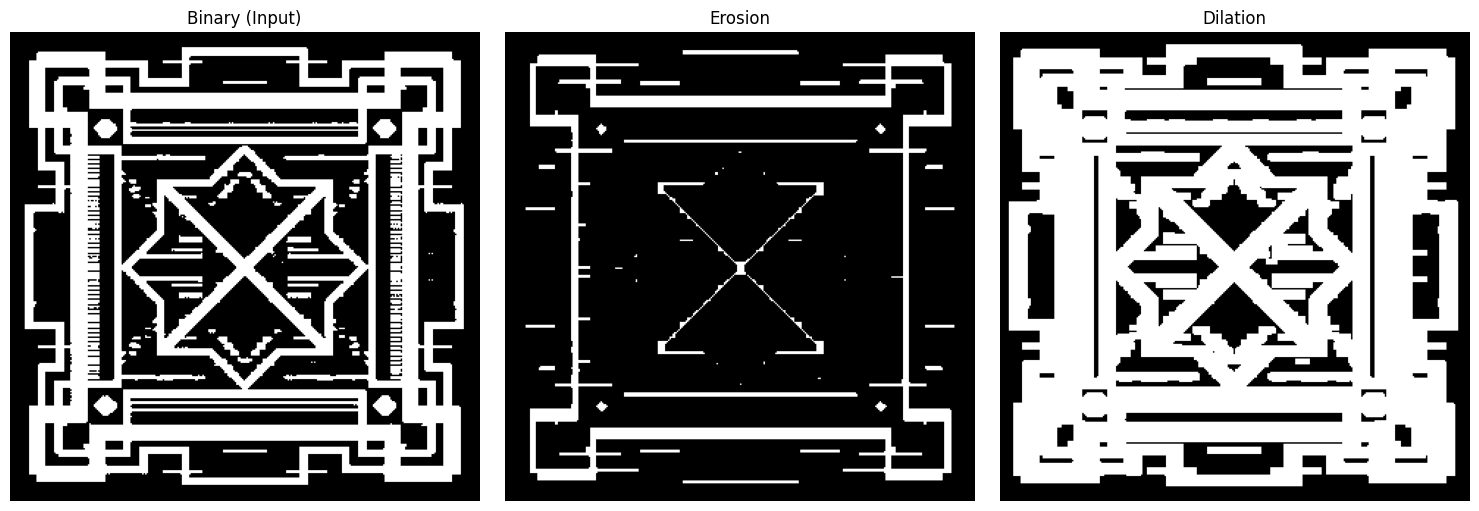

In [18]:
#Display Erosion and Dilation
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, im, title in zip(axes, [binary, eroded, dilated],
                          ["Binary (Input)", "Erosion", "Dilation"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

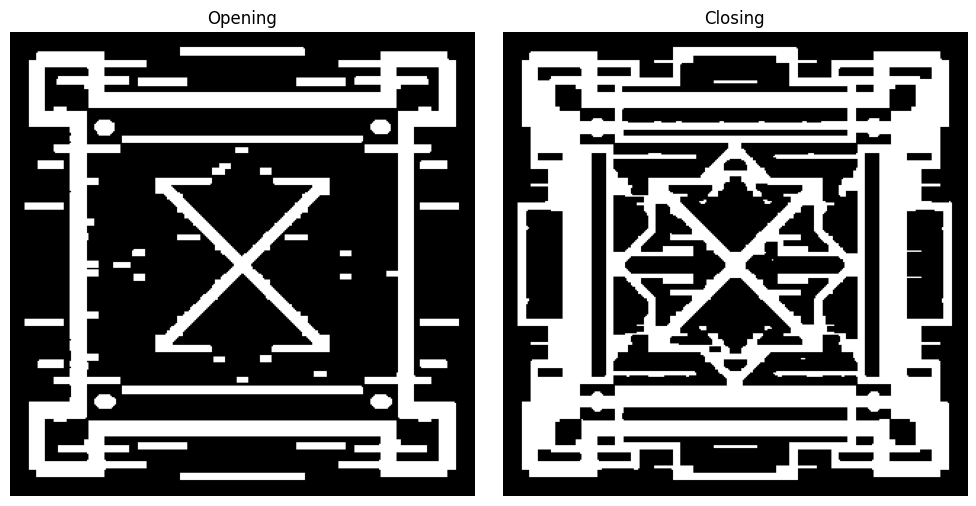

Opening foreground: 26646
Closing foreground: 44615


In [19]:
#Opening and Closing

# Opening = erosion followed by dilation
eroded = erosion(binary, SE)
opening = dilation(eroded, SE)

# Closing = dilation followed by erosion
dilated = dilation(binary, SE)
closing = erosion(dilated, SE)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, im, title in zip(
    axes,
    [opening, closing],
    ["Opening", "Closing"]
):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Opening foreground:", np.sum(opening == 1))
print("Closing foreground:", np.sum(closing == 1))

WTH value range: 0 to 1
BTH value range: 0 to 1


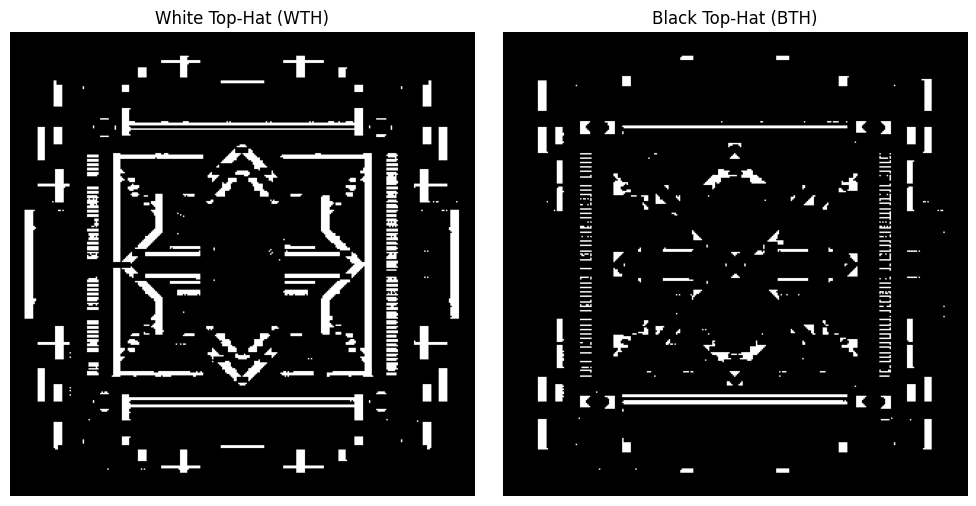

In [20]:
#White Top-Hat and Black Top-Hat

# White Top-Hat = Original - Opening
WTH = binary.astype(int) - opening.astype(int)

# Black Top-Hat = Closing - Original
BTH = closing.astype(int) - binary.astype(int)

print("WTH value range:", WTH.min(), "to", WTH.max())
print("BTH value range:", BTH.min(), "to", BTH.max())

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(WTH, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("White Top-Hat (WTH)")
axes[0].axis("off")

axes[1].imshow(BTH, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Black Top-Hat (BTH)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Final value range: -1 to 2
Final unique values: [-1  0  1  2]


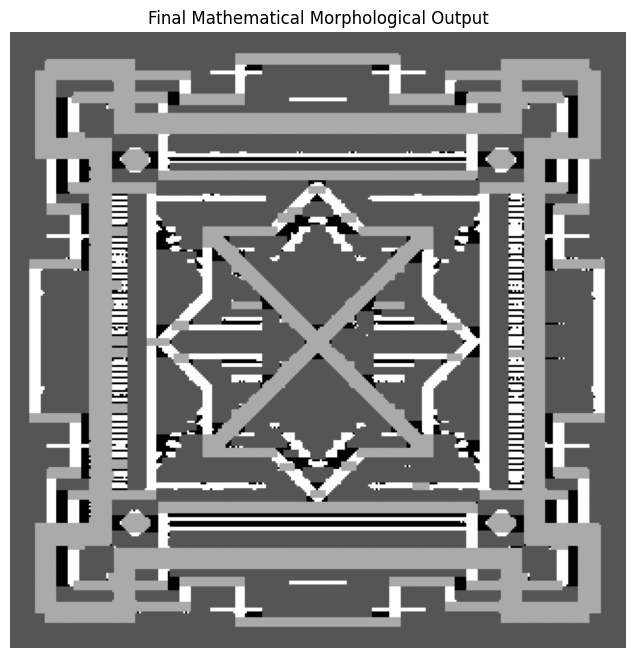

In [21]:
#Final Mathematical Morphological Output

#Final = Original + White Top-Hat - Black Top-Hat
final = binary.astype(int) + WTH - BTH

print("Final value range:", final.min(), "to", final.max())
print("Final unique values:", np.unique(final))


final_display = np.zeros_like(final, dtype=np.uint8)

final_display[final == -1] = 0
final_display[final == 0] = 85
final_display[final == 1] = 170
final_display[final == 2] = 255

plt.figure(figsize=(8, 8))
plt.imshow(final_display, cmap="gray", vmin=0, vmax=255)
plt.title("Final Mathematical Morphological Output")
plt.axis("off")
plt.show()

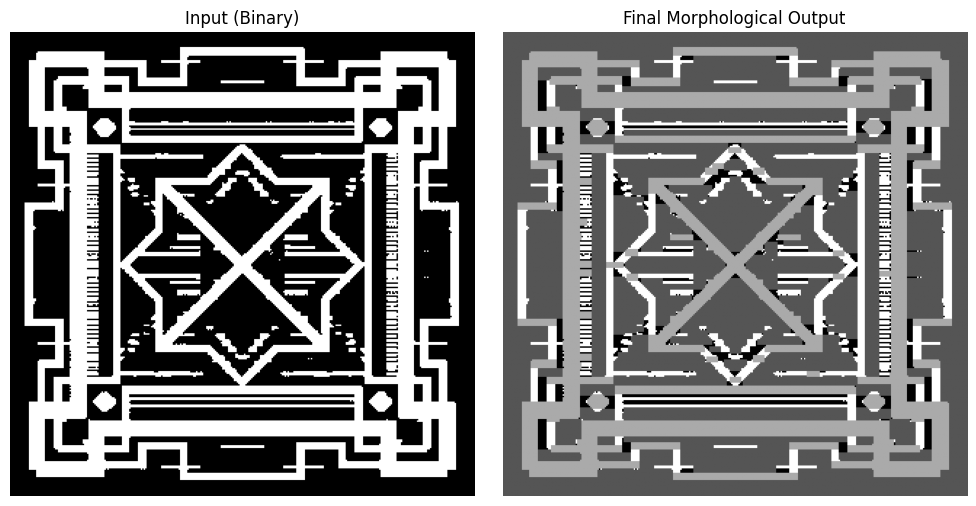

In [22]:
#Input vs Final Output Comparison

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(binary, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Input (Binary)")
axes[0].axis("off")

axes[1].imshow(final_display, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Final Morphological Output")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [23]:
#Full Morphological Pipeline

def run_morphology_pipeline(binary_img, se):

    #Erosion
    eroded = erosion(binary_img, se)

    #Dilation
    dilated = dilation(binary_img, se)

    #Opening = erosion followed by dilation
    opening = dilation(eroded, se)

    #Closing = dilation followed by erosion
    closing = erosion(dilated, se)

    # White Top-Hat
    WTH = binary_img.astype(int) - opening.astype(int)

    # Black Top-Hat
    BTH = closing.astype(int) - binary_img.astype(int)

    #Final morphological enhancement
    final = binary_img.astype(int) + WTH - BTH

    return {
        "eroded": eroded,
        "dilated": dilated,
        "opening": opening,
        "closing": closing,
        "WTH": WTH,
        "BTH": BTH,
        "final": final
    }

In [24]:
#Comparing SE sizes 3x8, 4x8, 5x8, 6x8
se_heights = [3, 4, 5, 6]
se_results = {}

for h in se_heights:
    se_h = np.ones((h, 8), dtype=np.uint8)
    se_results[h] = run_morphology_pipeline(binary, se_h)
    r = se_results[h]["final"]

    print(
        f"SE {h}x8 -> final range: "
        f"{r.min()} to {r.max()}, "
        f"unique: {np.unique(r)}"
    )

SE 3x8 -> final range: -1 to 2, unique: [-1  0  1  2]
SE 4x8 -> final range: -1 to 2, unique: [-1  0  1  2]
SE 5x8 -> final range: -1 to 2, unique: [-1  0  1  2]
SE 6x8 -> final range: -1 to 2, unique: [-1  0  1  2]


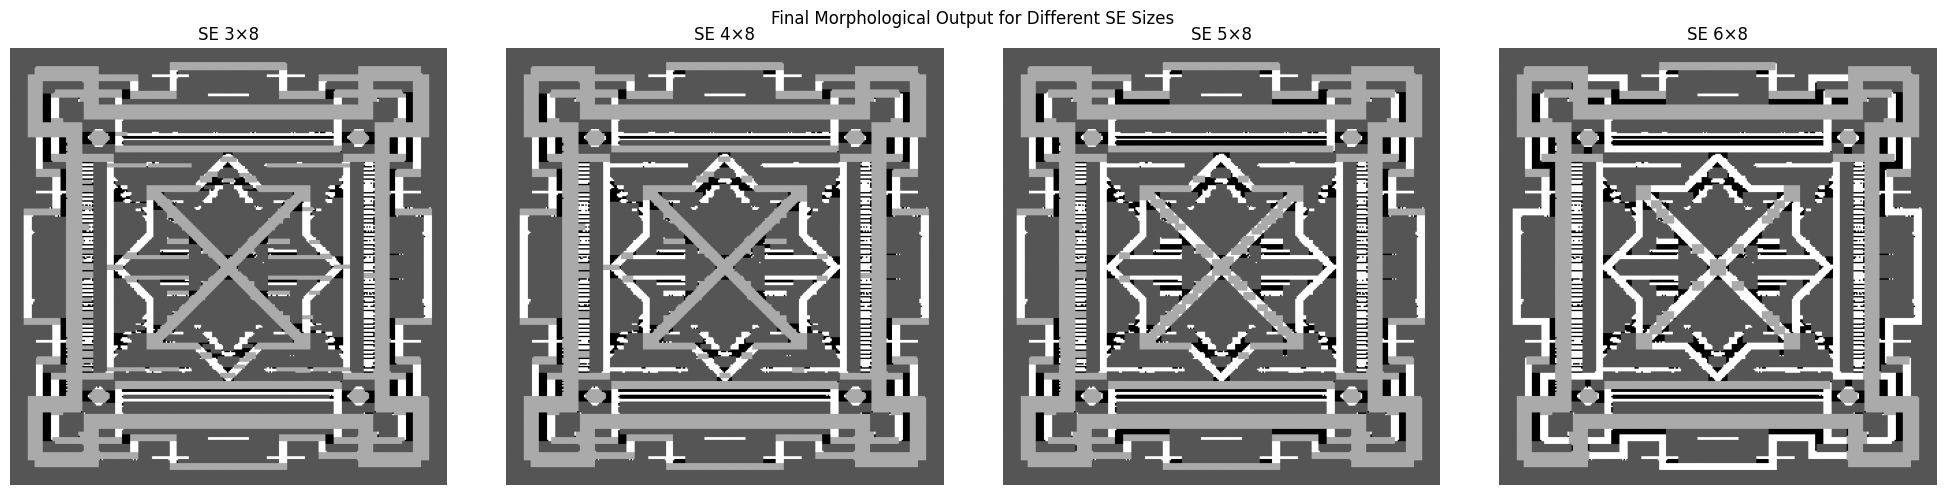

In [25]:
#Final Output for Each SE Size

fig, axes = plt.subplots(
    1,
    len(se_heights),
    figsize=(5 * len(se_heights), 5)
)

for ax, h in zip(axes, se_heights):

    result = se_results[h]["final"]

    # Convert raw mathematical result into a display image
    result_display = np.zeros_like(result, dtype=np.uint8)

    result_display[result == -1] = 0
    result_display[result == 0] = 85
    result_display[result == 1] = 170
    result_display[result == 2] = 255

    ax.imshow(result_display, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"SE {h}×8")
    ax.axis("off")

plt.suptitle("Final Morphological Output for Different SE Sizes")
plt.tight_layout()
plt.show()

In [26]:
#Morphological Verification

print("Binary unique values:", np.unique(binary))

print("Erosion unique values:", np.unique(eroded))
print("Dilation unique values:", np.unique(dilated))

print("Opening unique values:", np.unique(opening))
print("Closing unique values:", np.unique(closing))

print("WTH unique values:", np.unique(WTH))
print("BTH unique values:", np.unique(BTH))

print("Final unique values:", np.unique(final))

print("\nOpening > Binary:",
      np.sum(opening > binary))

print("Closing < Binary:",
      np.sum(closing < binary))

Binary unique values: [0 1]
Erosion unique values: [0 1]
Dilation unique values: [0 1]
Opening unique values: [0 1]
Closing unique values: [0 1]
WTH unique values: [0 1]
BTH unique values: [0 1]
Final unique values: [-1  0  1  2]

Opening > Binary: 0
Closing < Binary: 0
